# Practical QD blinking analysis

Companion workflow for *A practical guide for wide-field imaging of quantum dot blinking*.

Run the cells from top to bottom after restarting the kernel. The default run is a **synthetic demonstration**, not paper data. Set `DEMO_MODE = False` and supply verified acquisition metadata to analyse a real RAW file. Keep `qd_blinking.py` beside this notebook; it contains the readable, tested numerical functions.

This notebook identifies spatial candidates, fits circular Gaussians, extracts aperture-mean / annular-median trajectories, plots histograms, and exports data and parameters. It does **not** establish single-QD identity, implement a security protocol, or provide a validated automatic ON/OFF classifier. Fixed apertures assume stationary, adequately focused features; inspect drift, neighbouring emitters and changing background.

Install the versions in `requirements.txt` into a Python 3.12 environment, then launch Jupyter. See README for commands, output definitions and release checks.


In [14]:
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from IPython.display import display
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
from qd_blinking import (
    AnalysisConfig, select_input_file, load_raw_video, timing, projections, fit_candidates,
    extract_trace, trace_statistics, threshold_runs, synthetic_video,
    export_results, sha256_file,
)
plt.rcParams.update({'figure.dpi': 120, 'figure.figsize': (8, 6)})


## 1. Configuration

The supplied notebook used **1024 × 1024** pixels and its saved output reported 1000 frames. The manuscript SI currently says 1058 × 1058: confirm the RAW metadata before submission. Neither value can be inferred reliably just from divisibility of the file size.

`RAW_DTYPE='<u2'` means unpacked little-endian unsigned 16-bit values. This is an explicit input assumption requiring verification; packed formats, row padding and per-frame headers are not supported. `EXPOSURE_TIME_S` is the integration time, not necessarily the interval between frames. Supply `FRAME_INTERVAL_S` or a CSV with a `time_s` column of frame-start timestamps. Without either, plots use frame index and exported seconds are blank.

Detection settings retain the original starting values; thresholds are relative to the full-image min/max normalisation and may need adjustment for each recording. `R` is the fitted Gaussian **standard deviation σ**, not FWHM or the LoG display radius √2σ. The fitted model is A exp(−((x−x₀)²+(y−y₀)²)/(2R²)) + B.

For experimental data, leave `RAW_FILE=None`: the load cell opens a file picker, or prompts for a path if no graphical picker is available. Set `USE_TIMESTAMP_FILE=True` to select a timing CSV in the same way. On remote Jupyter, files must be visible to the Python kernel; this does not upload a multi-gigabyte RAW file through the browser. Rerunning the configuration cell resets the selections.


In [15]:
# Quick code section to quickly check that the file wanting to be loaded can be seen before comitting to any further processing

RAW_FILE = "/Users/william/Documents/UNI/MASTERS PROJECT/WT_MastersRepo/Exp_Data/qdb_20260824_102327.raw"  # With DEMO_MODE=False, choose a recording when the load cell runs.
raw_path = Path(RAW_FILE)

print("File Exists: ", raw_path.is_file())
print("File Size: ", round(raw_path.stat().st_size /1e9, 2), "GB")


File Exists:  True
File Size:  2.1 GB


In [16]:
DEMO_MODE = False
RAW_FILE = Path("/Users/william/Documents/UNI/MASTERS PROJECT/WT_MastersRepo/Exp_Data/qdb_20260824_102327.raw")  # With DEMO_MODE=False, choose a recording when the load cell runs.
IMAGE_WIDTH = 1024
IMAGE_HEIGHT = 1024
RAW_HEADER_BYTES = 0
RAW_DTYPE = '<u2'
EXPECTED_FRAMES = 1000  # Set None only if the frame count is genuinely unknown.
EXPOSURE_TIME_S = 0.050
FRAME_INTERVAL_S = None  # Set from acquisition metadata, not just exposure.
USE_TIMESTAMP_FILE = False  # If True, also choose a CSV with a time_s column.
TIMESTAMPS_CSV = None
HASH_INPUT = True       # Streams the RAW file once; can be slow for large files.

CONFIG = AnalysisConfig()  # See qd_blinking.py for all adjustable settings.
CONFIG.validate()

# Optional exploratory thresholds, chosen AFTER inspecting corrected traces and histograms.
# Units: background-corrected MEAN pixel counts, NOT raw camera offset or integrated counts.
# Example syntax only: {3: 25.0}; no universal threshold is prescribed.
THRESHOLDS = {}

CANDIDATES_TO_PLOT = None  # None plots first 3 retained; or give original IDs, e.g. [3, 38].
SAVE_FIGURES = True
OUTPUT_ROOT = Path('qd_blinking_results')


## 2. Load a video and report its metadata

The synthetic sequence contains two periodically switching Gaussian spots plus noise; it tests the workflow, not the physical statistics of QD blinking. Real RAW data are read-only memory-mapped. The projections and local apertures are processed in chunks to avoid allocating another entire video.


In [17]:
if DEMO_MODE:
    video, synthetic_truth = synthetic_video()
    source_name = 'SYNTHETIC_DEMO'
    exposure_s, frame_interval_s = 0.05, 0.05
    input_hash, timestamp_hash = None, None
    supplied_timestamps = None
else:
    if RAW_FILE is None:
        RAW_FILE = select_input_file()
    if USE_TIMESTAMP_FILE and TIMESTAMPS_CSV is None:
        TIMESTAMPS_CSV = select_input_file("frame-start timestamps CSV", "*.csv")
    video = load_raw_video(RAW_FILE, IMAGE_WIDTH, IMAGE_HEIGHT,
                           RAW_HEADER_BYTES, RAW_DTYPE, EXPECTED_FRAMES)
    synthetic_truth = None
    source_name = RAW_FILE.name
    exposure_s, frame_interval_s = EXPOSURE_TIME_S, FRAME_INTERVAL_S
    input_hash = sha256_file(RAW_FILE) if HASH_INPUT else None
    supplied_timestamps = (pd.read_csv(TIMESTAMPS_CSV)['time_s'].to_numpy()
                           if TIMESTAMPS_CSV is not None else None)
    timestamp_hash = sha256_file(TIMESTAMPS_CSV) if TIMESTAMPS_CSV is not None else None

n_frames, height, width = video.shape
time_s, regular_interval = timing(n_frames, exposure_s, frame_interval_s, supplied_timestamps)
time_known = bool(np.isfinite(time_s).all())
plot_x = time_s if time_known else np.arange(n_frames)
x_label = 'Elapsed frame-start time (s)' if time_known else 'Frame index'
print(f'Source: {source_name}; shape: {video.shape}; stored dtype: {video.dtype}')
print(f'Exposure: {exposure_s:g} s; total integration: {n_frames*exposure_s:g} s')
if time_known:
    print(f'First-to-last frame-start span: {time_s[-1]:g} s')
    print(f'Acquisition span through final exposure: {time_s[-1]+exposure_s:g} s')
    print(f'Regular frame interval: {regular_interval}')
else:
    print('Frame timing unknown: seconds and dwell-time summaries are disabled.')
if DEMO_MODE:
    print('SYNTHETIC DEMONSTRATION ONLY — not results from the paper.')


Source: qdb_20260824_102327.raw; shape: (1000, 1024, 1024); stored dtype: uint16
Exposure: 0.05 s; total integration: 50 s
Frame timing unknown: seconds and dwell-time summaries are disabled.


## 3. Mean and maximum projections

The mean image supplies detection. The maximum projection is a diagnostic only; it can reveal low-ON-fraction features but also emphasises noise. No drift correction, smoothing or intensity rescaling is applied to the extracted traces.


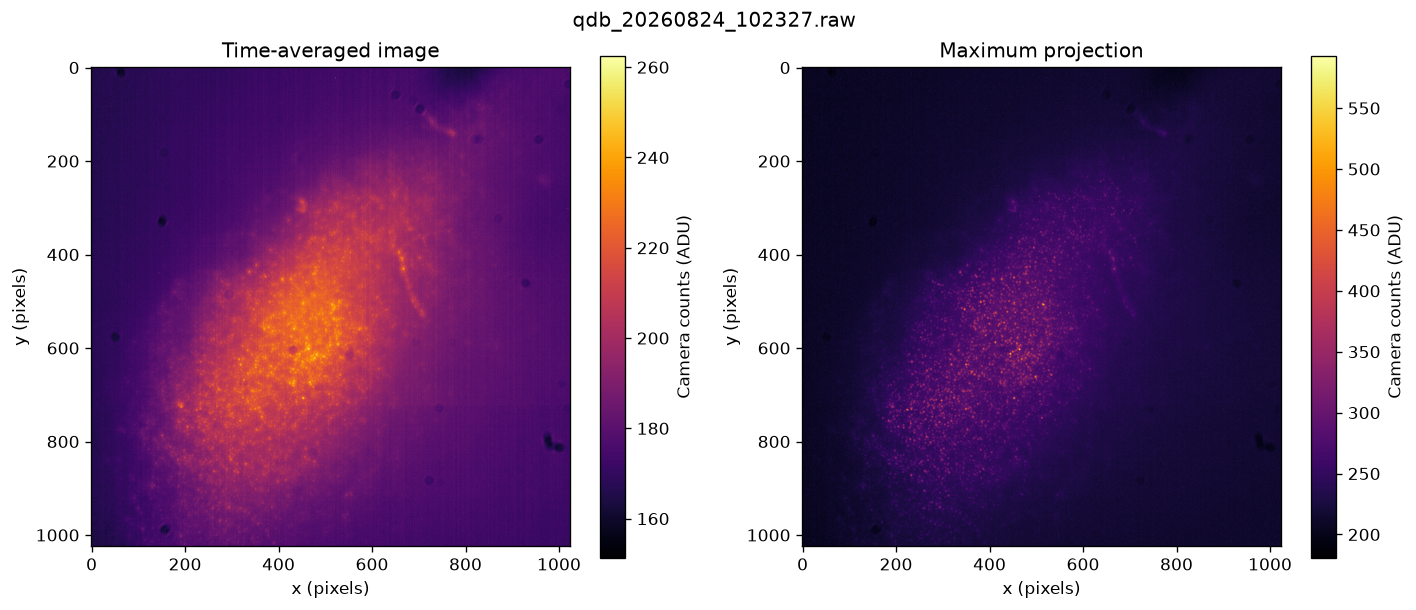

In [18]:
mean_image, max_projection = projections(video, CONFIG.chunk_frames)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, im, title in zip(axes, [mean_image, max_projection], ['Time-averaged image', 'Maximum projection']):
    artist = ax.imshow(im, cmap='inferno', origin='upper')
    ax.set(xlabel='x (pixels)', ylabel='y (pixels)', title=title)
    fig.colorbar(artist, ax=ax, label='Camera counts (ADU)')
fig.suptitle(source_name)
fig.tight_layout()
plt.show()
plt.close(fig)


## 4. Detect, fit and retain spatial candidates

The original LoG detection and circular Gaussian fit are retained. Fit quality, width, image-edge and duplicate-centre checks are now recorded for every detection, including failures. A complete annulus is required so edge truncation cannot silently change the measurement. Fits at optimiser bounds are rejected; a non-finite covariance is flagged for inspection, not silently interpreted as an uncertainty estimate. The 13 × 13 fitting window may constrain broad features poorly; inspect the fit residual and images.

Candidate IDs remain those of the original detections and may have gaps. They are consistent within a run, not persistent identities across recordings or parameter changes. The conservative quality exclusions can change the retained count relative to the original notebook; they are recorded in `all_candidates.csv`.


In [19]:
fits = fit_candidates(mean_image, CONFIG)
retained = fits.loc[fits['retained'].astype(bool)].copy()
print(f'Detected: {len(fits)}; successful fits: {int(fits.fit_ok.sum())}; retained: {len(retained)}')
display(fits['reason'].value_counts().rename('count').to_frame())
display(retained[['candidate_id', 'x', 'y', 'R', 'amplitude', 'fit_rmse', 'fit_covariance_finite']])
if retained.empty:
    print('No candidates retained. Inspect the input and detection settings; empty exports are valid.')


Detected: 264; successful fits: 263; retained: 168


,count
reason,
retained,168
width_outside_range,94
duplicate_fitted_centre,1
fit_window_at_edge,1


,candidate_id,x,y,R,amplitude,fit_rmse,fit_covariance_finite
0,1,452.800828,706.836582,1.637609,44.996807,2.888162,True
1,2,464.054173,601.701621,1.684931,30.266898,4.728273,True
2,3,667.021776,430.300938,2.022593,29.615244,3.289222,True
3,4,205.045549,768.342618,1.578358,31.360979,2.577081,True
4,5,318.990623,635.325971,1.591299,30.580475,2.592365,True
...,...,...,...,...,...,...,...
256,257,301.030385,744.887955,5.667131,10.719999,3.107510,True
260,261,451.615031,739.154084,1.728935,12.014807,3.363936,True
261,262,487.123341,526.732261,1.557416,11.755929,2.740788,True
262,263,306.827061,621.052727,2.069406,10.890496,2.528395,True


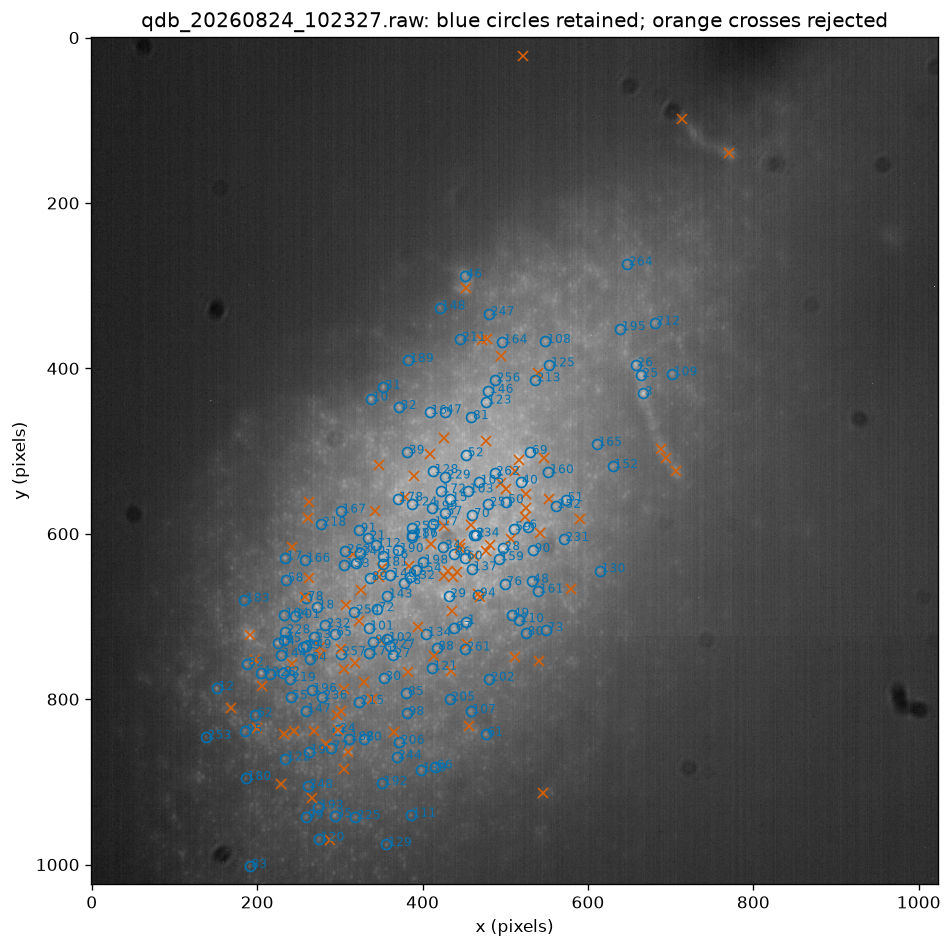

In [20]:
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(mean_image, cmap='gray', origin='upper')
for row in fits.itertuples():
    if not row.fit_ok:
        continue
    colour = '#0072B2' if row.retained else '#D55E00'
    ax.plot(row.x, row.y, 'o' if row.retained else 'x', color=colour,
            markerfacecolor='none', markersize=6)
    if row.retained:
        ax.text(row.x+2, row.y+2, str(int(row.candidate_id)), color=colour, fontsize=7)
ax.set(xlabel='x (pixels)', ylabel='y (pixels)',
       title=f'{source_name}: blue circles retained; orange crosses rejected')
fig.tight_layout()
plt.show()
plt.close(fig)


## 5. Extract the trajectories

For each frame, corrected mean intensity = aperture mean − annular median. Pixel centres within radius 3 form the signal mask; centres at radii 5–8 form the background mask, including boundaries. The masks use the fitted subpixel centre, so the aperture is **not always 29 pixels**. Counts are ADU, not photons or electrons. Integrated corrected counts = corrected mean × the actual aperture pixel count; no camera gain or encircled-energy correction is assumed.

Nearby features can contaminate either region. The median makes the annulus less sensitive to isolated bright pixels but does not eliminate systematic contamination. A trace's standard deviation includes blinking and is not an independently measured noise level or SNR. Raw background levels can contain a camera offset, so a naive signal/background ratio is omitted.


In [21]:
traces = {int(row.candidate_id): extract_trace(video, row.x, row.y, CONFIG)
          for row in retained.itertuples()}
statistics = trace_statistics(traces)
display(statistics)
print(f'Extracted {len(traces)} trajectories of {n_frames} frames each.')


,candidate_id,mean_corrected_counts,median_corrected_counts,std_corrected_counts,min_corrected_counts,max_corrected_counts,mean_background_counts,aperture_pixels,annulus_pixels,saturated_aperture_fraction
0,1,22.285071,14.946429,22.483104,-7.464286,143.142857,214.0720,28,121,NaN
1,2,16.258778,11.166667,17.961308,-9.962963,163.703704,231.3440,27,123,NaN
2,3,18.828741,14.851852,16.255025,-6.259259,65.000000,210.8360,27,123,NaN
3,4,15.578222,12.648148,13.525558,-7.148148,77.111111,199.2330,27,123,NaN
4,5,16.166385,11.288462,18.451188,-12.038462,124.769231,216.5230,26,123,NaN
...,...,...,...,...,...,...,...,...,...,...
163,257,3.126222,2.518519,5.520314,-10.185185,34.037037,212.6260,27,123,NaN
164,261,6.793571,3.857143,10.269245,-9.750000,88.464286,208.8000,28,121,NaN
165,262,6.017759,2.862069,11.303465,-8.551724,62.137931,226.5660,29,123,NaN
166,263,6.192643,4.607143,7.412895,-10.107143,43.321429,211.1015,28,124,NaN


Extracted 168 trajectories of 1000 frames each.


## 6. Inspect candidates, histograms and optional thresholds

Each figure shows the same unmodified data in the raw and corrected panels. The corrected trace is checked against raw signal minus local background before plotting. Pixel-centre coordinates in the image and aperture overlay agree.

Thresholds are optional and manual. Choose them from well-separated populations and assess sensitivity; no threshold is automatically inferred from the annular median fluctuations. Labels mean **above/below the selected threshold**, not established physical ON/OFF states. OFF assignment additionally requires consistency with local background/noise. Boundary runs are censored and never presented as complete dwell events. Irregular timing retains frame counts but disables this simple conversion to dwell seconds.


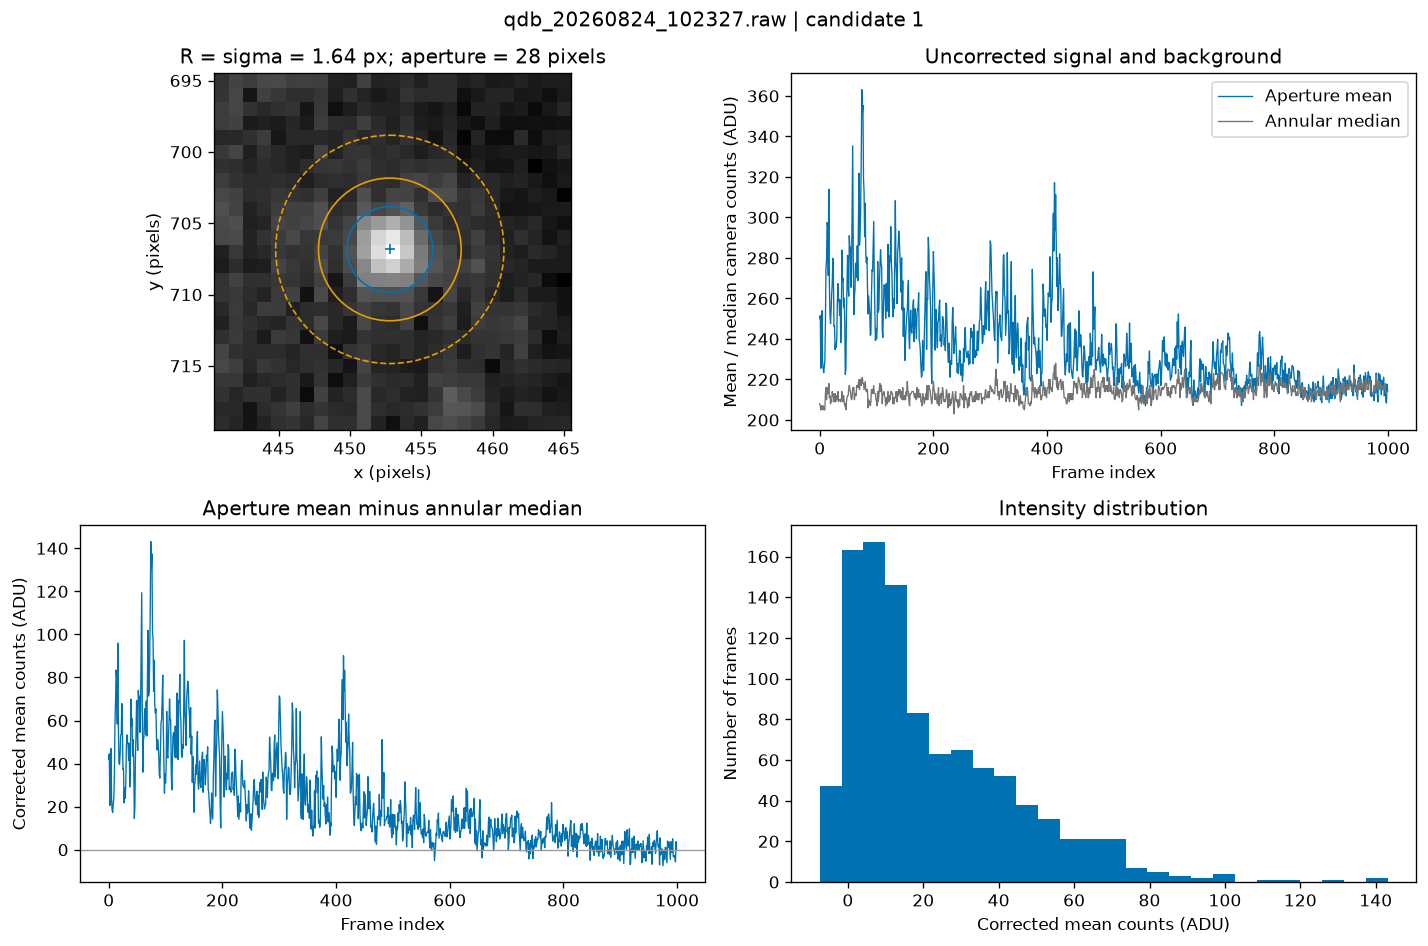

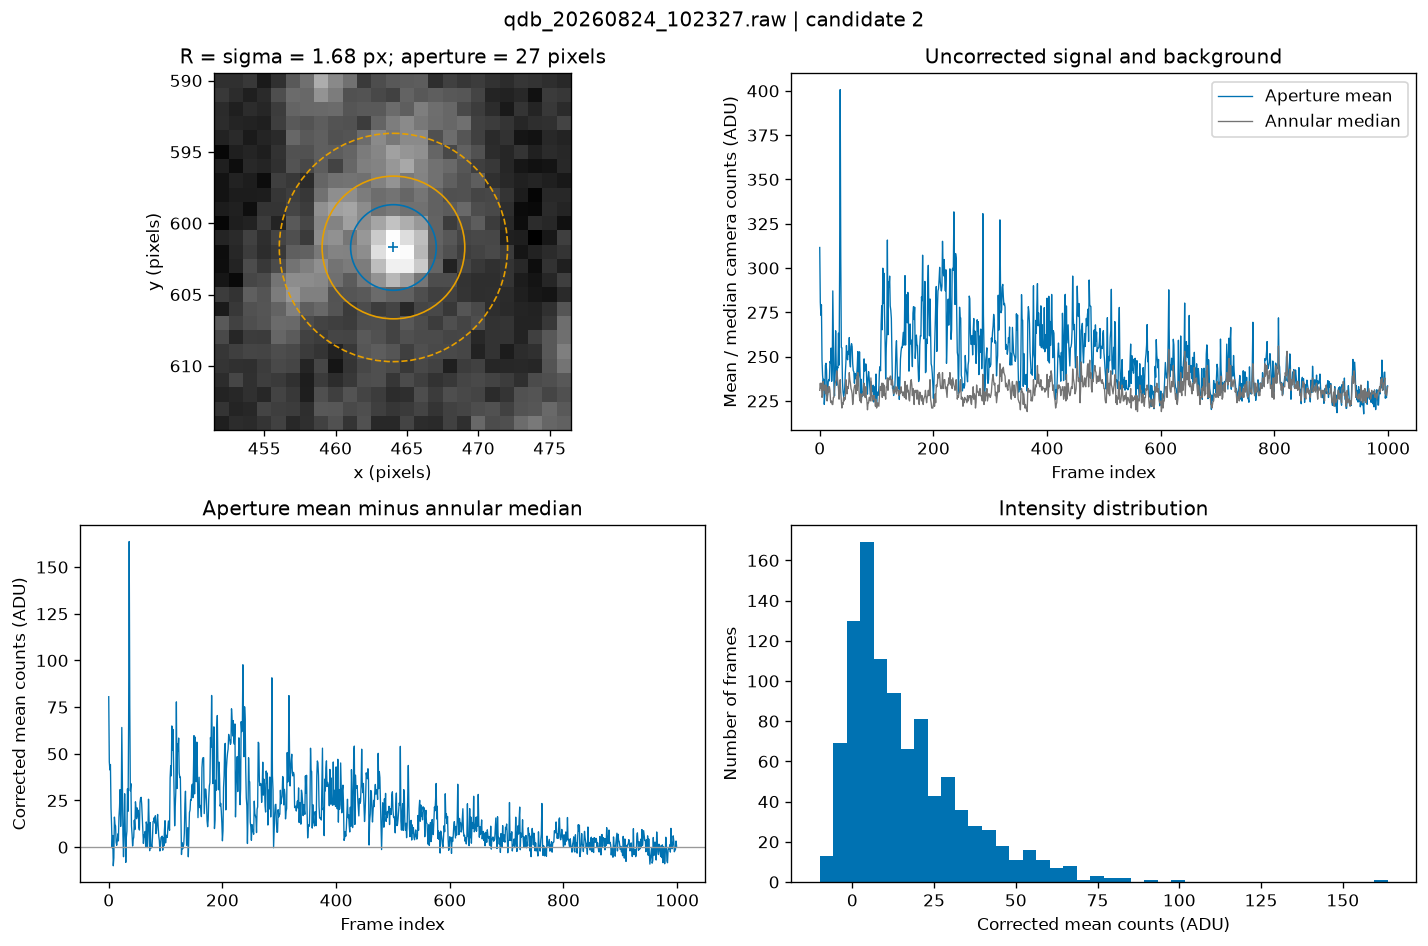

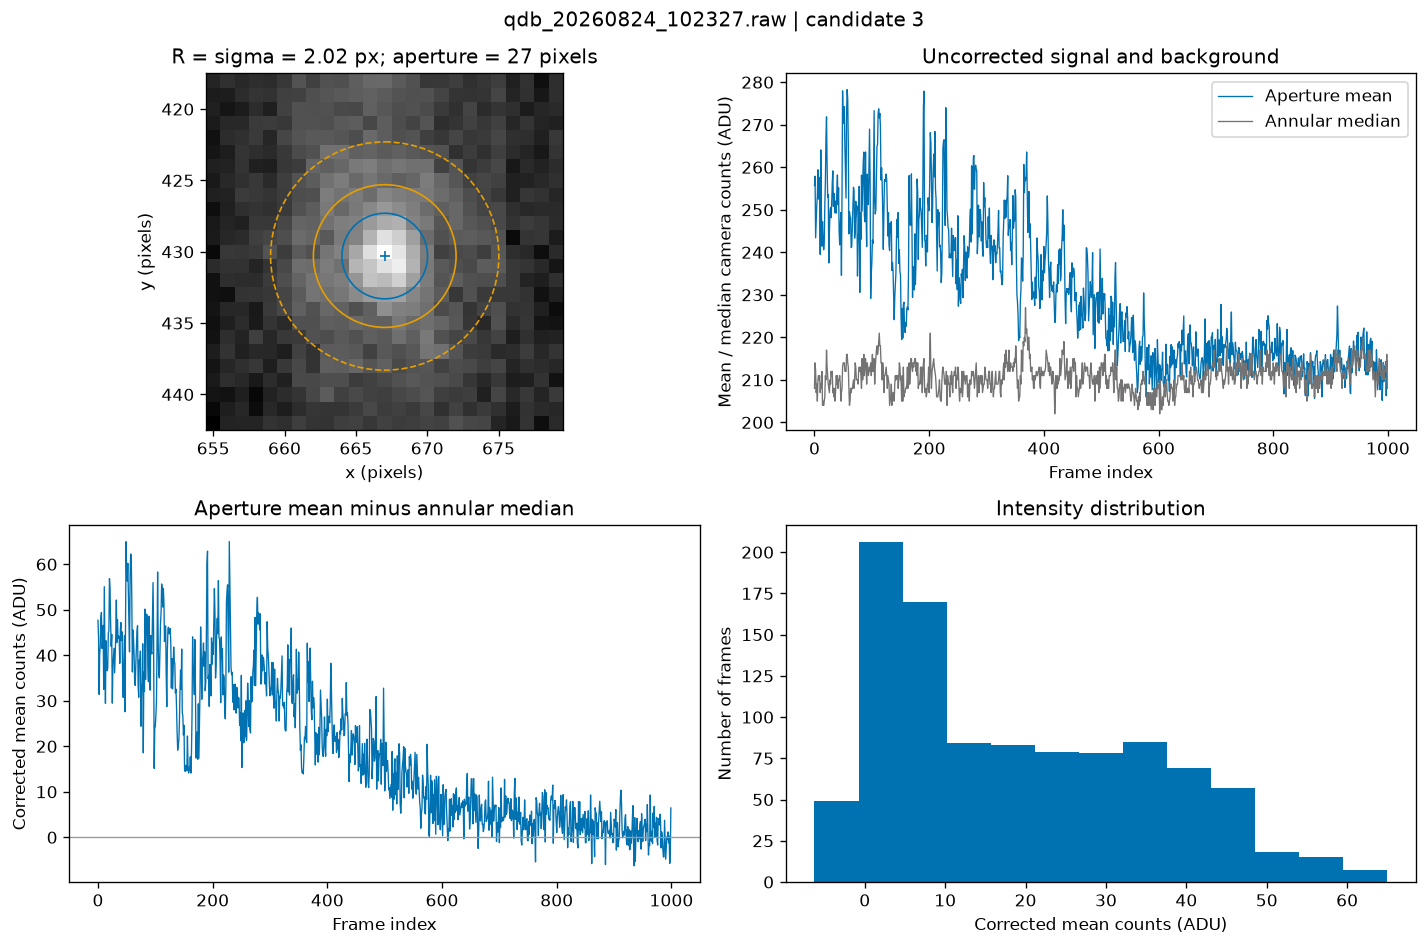

In [22]:
def plot_candidate(candidate_id):
    if candidate_id not in traces:
        raise ValueError(f'Candidate {candidate_id} is not retained. Available IDs: {list(traces)}')
    row = retained.loc[retained.candidate_id == candidate_id].iloc[0]
    tr = traces[candidate_id]
    np.testing.assert_allclose(tr['corrected'], tr['signal']-tr['background'], rtol=0, atol=0)
    x, y = float(row.x), float(row.y)
    r = max(12, int(np.ceil(CONFIG.background_outer))+2)
    x0, x1 = max(0, int(round(x))-r), min(width, int(round(x))+r+1)
    y0, y1 = max(0, int(round(y))-r), min(height, int(round(y))+r+1)
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    ax = axes[0, 0]
    ax.imshow(mean_image[y0:y1, x0:x1], cmap='gray', origin='upper',
              extent=(x0-0.5, x1-0.5, y1-0.5, y0-0.5))
    for radius, colour, style in [(CONFIG.aperture_radius, '#0072B2', '-'),
                                  (CONFIG.background_inner, '#E69F00', '-'),
                                  (CONFIG.background_outer, '#E69F00', '--')]:
        ax.add_patch(Circle((x,y), radius, fill=False, color=colour, linestyle=style))
    ax.plot(x, y, '+', color='#0072B2')
    ax.set(xlabel='x (pixels)', ylabel='y (pixels)',
           title=f'R = sigma = {row.R:.2f} px; aperture = {tr["aperture_pixels"]} pixels')
    ax = axes[0, 1]
    ax.plot(plot_x, tr['signal'], color='#0072B2', lw=0.8, label='Aperture mean')
    ax.plot(plot_x, tr['background'], color='0.45', lw=0.8, label='Annular median')
    ax.set(xlabel=x_label, ylabel='Mean / median camera counts (ADU)', title='Uncorrected signal and background')
    ax.legend()
    ax = axes[1, 0]
    ax.plot(plot_x, tr['corrected'], color='#0072B2', lw=0.8)
    ax.axhline(0, color='0.6', lw=0.8)
    ax.set(xlabel=x_label, ylabel='Corrected mean counts (ADU)', title='Aperture mean minus annular median')
    axes[1, 1].hist(tr['corrected'], bins='auto', color='#0072B2')
    axes[1, 1].set(xlabel='Corrected mean counts (ADU)', ylabel='Number of frames', title='Intensity distribution')
    if candidate_id in THRESHOLDS:
        th = THRESHOLDS[candidate_id]
        ax.axhline(th, color='#D55E00', ls='--', label='Exploratory threshold')
        ax.legend()
        axes[1, 1].axvline(th, color='#D55E00', ls='--')
    fig.suptitle(f'{source_name} | candidate {candidate_id}')
    fig.tight_layout()
    return fig

selected_ids = (list(traces)[:3] if CANDIDATES_TO_PLOT is None else CANDIDATES_TO_PLOT)
for cid in selected_ids:
    fig = plot_candidate(int(cid))
    plt.show()
    plt.close(fig)


In [23]:
# Optional: edit THRESHOLDS in the configuration cell, then rerun from that cell.
if set(THRESHOLDS)-set(traces):
    raise ValueError('Thresholds must use retained candidate IDs from this run.')
for cid, th in THRESHOLDS.items():
    runs = threshold_runs(traces[cid]['corrected'], th, regular_interval)
    print(f'Candidate {cid}: fraction of frames above threshold = '
          f'{np.mean(traces[cid]["corrected"] > th):.3f}; transitions = {len(runs)-1}')
    display(runs)
if not THRESHOLDS:
    print('Threshold analysis disabled; extraction, histograms and CSV export remain available.')


Threshold analysis disabled; extraction, histograms and CSV export remain available.


## 7. Export data, analysis settings and provenance

A fresh run directory prevents stale figures or CSVs from being mixed with a new analysis. It contains all detections and rejection reasons, retained candidates, trace statistics, full trajectories, optional threshold runs with censor flags, and JSON parameters/software versions. Inputs are identified by basename and SHA-256 when enabled. Selected figures are saved as PNG and SVG when `SAVE_FIGURES=True`.

To recreate the paper panels exactly, the authors must additionally provide the actual input files and a mapping of each panel to video filename/hash, candidate ID, fitted position, frame range and acquisition timestamps. This demonstration is not a verified reconstruction of Figure 9.


In [24]:
run_name = source_name.replace('.', '_') + '_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
run_metadata = {
    'source_name': source_name, 'synthetic_demo': DEMO_MODE,
    'input_sha256': input_hash, 'input_hash_enabled': HASH_INPUT and not DEMO_MODE,
    'video_shape_frames_height_width': list(video.shape),
    'raw_format': None if DEMO_MODE else {'width': IMAGE_WIDTH, 'height': IMAGE_HEIGHT,
        'dtype': RAW_DTYPE, 'header_bytes': RAW_HEADER_BYTES, 'expected_frames': EXPECTED_FRAMES},
    'exposure_time_s': exposure_s, 'configured_frame_interval_s': frame_interval_s,
    'timestamps_file': None if DEMO_MODE or TIMESTAMPS_CSV is None else Path(TIMESTAMPS_CSV).name,
    'timestamps_sha256': timestamp_hash,
    'timestamp_origin_s': None if supplied_timestamps is None else float(supplied_timestamps[0]),
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'selected_plot_candidate_ids': [int(cid) for cid in selected_ids],
    'save_figures': SAVE_FIGURES, 'synthetic_truth': synthetic_truth,
}
run_dir = export_results(OUTPUT_ROOT/run_name, fits, traces, time_s, run_metadata, CONFIG,
                         thresholds=THRESHOLDS, regular_interval=regular_interval)
if SAVE_FIGURES:
    for cid in selected_ids:
        fig = plot_candidate(int(cid))
        fig.savefig(run_dir/f'candidate_{int(cid):04d}.png', dpi=300)
        fig.savefig(run_dir/f'candidate_{int(cid):04d}.svg')
        plt.close(fig)
print(f'Analysis complete: {run_dir.resolve()}')
print('Check exported candidate IDs, mask counts, time metadata and the corresponding figures.')


Analysis complete: /Users/william/Documents/UNI/MASTERS PROJECT/WT_MastersRepo/qd_blinking_supplementary_code/qd_blinking_results/qdb_20260824_102327_raw_20261020T145929_676324Z
Check exported candidate IDs, mask counts, time metadata and the corresponding figures.


## Interpretation limits and method references

- R is sigma in the circular 2D Gaussian, not a proof of one emitter. Overlap, drift, aberrations, unequal brightness and ON fraction affect detection and fitting.
- Detection uses the mean image; short-lived or rarely bright features may be missed. No automatic single-emitter certification is made.
- Threshold runs are sampled descriptive intervals, not excited-state lifetimes or a statistically fitted dwell-time distribution. Boundary events are censored; camera integration, gaps and noise limit temporal resolution.
- `saturation_adu` should be supplied from the camera mode if saturation checking is wanted. Missing saturation metadata is exported as unknown, not as zero saturation.
- This code does not validate the paper's irradiance, frame geometry, camera conversion factor or security claims.

Method context: [scikit-image LoG documentation](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.blob_log); [Lagerholm et al., 2006](https://pmc.ncbi.nlm.nih.gov/articles/PMC1578492/). Software release licence and ownership are for the authors/institution to confirm; none is assigned by this review.
